In [3]:
from pathlib import Path
import pandas as pd

ROOT = Path('/content/drive/MyDrive')

# Locate the TB metadata file
matches = list(ROOT.rglob('shenzhen_metadata.csv'))

print("Metadata files found:", len(matches))

for path in matches:
    print(path)

if matches:
    METADATA_PATH = matches[0]
    IMAGE_DIR = METADATA_PATH.parent / 'images'
    BASE = METADATA_PATH.parent.parent

    print("\nImages folder exists:", IMAGE_DIR.exists())
    print("Metadata file exists:", METADATA_PATH.exists())
    print("PNG image count:", len(list(IMAGE_DIR.glob('*.png'))))

    df_tb = pd.read_csv(METADATA_PATH)
    print("\nMetadata rows:", len(df_tb))
    print("Columns:", df_tb.columns.tolist())
    display(df_tb.head())


Metadata files found: 1
/content/drive/MyDrive/Major_Project/Tuberculosis/data/shenzhen_metadata.csv

Images folder exists: True
Metadata file exists: True
PNG image count: 165

Metadata rows: 662
Columns: ['study_id', 'sex', 'age', 'findings']


,study_id,sex,age,findings
0,CHNCXR_0001_0.png,Male,45,normal
1,CHNCXR_0002_0.png,Male,63,normal
2,CHNCXR_0003_0.png,Female,48,normal
3,CHNCXR_0004_0.png,Male,58,normal
4,CHNCXR_0005_0.png,Male,28,normal


In [4]:
#metadata quality and class distribution
# Extract TB classification labels from filenames
# 0 = Normal, 1 = TB-related abnormality
df_tb["label"] = (
    df_tb["study_id"]
    .str.extract(r"_(0|1)\.png$", expand=False)
)

print("Total metadata records:", len(df_tb))
print("\nMissing values:")
print(df_tb.isna().sum())

print("\nDuplicate study IDs:",
      df_tb["study_id"].duplicated().sum())

print("\nTB class distribution:")
print(df_tb["label"].value_counts(dropna=False).sort_index())

print("\nAge summary:")
print(df_tb["age"].describe())

print("\nSex distribution:")
print(df_tb["sex"].value_counts(dropna=False))


Total metadata records: 662

Missing values:
study_id    0
sex         0
age         0
findings    0
label       0
dtype: int64

Duplicate study IDs: 0

TB class distribution:
label
0    326
1    336
Name: count, dtype: int64

Age summary:
count    662.000000
mean      35.575529
std       14.709271
min        1.000000
25%       26.000000
50%       33.000000
75%       43.000000
max       89.000000
Name: age, dtype: float64

Sex distribution:
sex
Male      460
Female    202
Name: count, dtype: int64


In [6]:
#Image–metadata matching
from pathlib import Path

# Get actual PNG filenames
image_files = {
    p.name for p in IMAGE_DIR.glob("*.png")
}

# Get filenames listed in metadata
metadata_files = set(df_tb["study_id"].astype(str).str.strip())

missing_images = metadata_files - image_files
extra_images = image_files - metadata_files

print("Images uploaded:", len(image_files))
print("Metadata records:", len(metadata_files))

print("\nMetadata records without images:", len(missing_images))
print("Images without metadata:", len(extra_images))

print("\nUpload complete:", len(image_files) == 662)

if len(image_files) == 662:
    print("All metadata matched:", len(missing_images) == 0
          and len(extra_images) == 0)
else:
    print("Upload still incomplete — wait before splitting.")


Images uploaded: 662
Metadata records: 662

Metadata records without images: 0
Images without metadata: 0

Upload complete: True
All metadata matched: True


In [7]:
#Label and Metadata Verification

import pandas as pd

# Convert Labels to Integers
df_tb["label"] = df_tb["label"].astype(int)

# Check Class Distribution
print("TB Class Distribution:")
print(df_tb["label"].value_counts().sort_index())

# Check Missing Values
print("\nMissing Values:")
print(df_tb[["study_id", "sex", "age", "label"]].isna().sum())

# Check Duplicate Image IDs
print("\nDuplicate Image IDs:", df_tb["study_id"].duplicated().sum())

# Check Age Statistics
print("\nAge Statistics:")
print(df_tb["age"].describe())

# Check Sex Distribution
print("\nSex Distribution:")
print(df_tb["sex"].value_counts(dropna=False))

TB Class Distribution:
label
0    326
1    336
Name: count, dtype: int64

Missing Values:
study_id    0
sex         0
age         0
label       0
dtype: int64

Duplicate Image IDs: 0

Age Statistics:
count    662.000000
mean      35.575529
std       14.709271
min        1.000000
25%       26.000000
50%       33.000000
75%       43.000000
max       89.000000
Name: age, dtype: float64

Sex Distribution:
sex
Male      460
Female    202
Name: count, dtype: int64


In [8]:
#Dataset Splitting

from sklearn.model_selection import train_test_split
from pathlib import Path
import pandas as pd

# Prepare Dataset
df_tb["label"] = df_tb["label"].astype(int)
df_tb["image_path"] = df_tb["study_id"].apply(
    lambda name: str(IMAGE_DIR / name)
)

# Training and Temporary Split (70% / 30%)
train_tb, temp_tb = train_test_split(
    df_tb,
    test_size=0.30,
    random_state=42,
    stratify=df_tb["label"]
)

# Validation and Test Split (15% / 15%)
val_tb, test_tb = train_test_split(
    temp_tb,
    test_size=0.50,
    random_state=42,
    stratify=temp_tb["label"]
)

# Save Fixed Splits
OUTPUT_DIR = BASE / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

train_tb.to_csv(OUTPUT_DIR / "tb_train.csv", index=False)
val_tb.to_csv(OUTPUT_DIR / "tb_val.csv", index=False)
test_tb.to_csv(OUTPUT_DIR / "tb_test.csv", index=False)

# Verify Split Sizes
print("Training images:", len(train_tb))
print("Validation images:", len(val_tb))
print("Testing images:", len(test_tb))
print("Total images:", len(train_tb) + len(val_tb) + len(test_tb))

# Verify Class Distribution
print("\nClass Distribution:")
print(pd.DataFrame({
    "Train": train_tb["label"].value_counts().sort_index(),
    "Validation": val_tb["label"].value_counts().sort_index(),
    "Test": test_tb["label"].value_counts().sort_index()
}).fillna(0).astype(int))

# Verify No Image Overlap
train_ids = set(train_tb["study_id"])
val_ids = set(val_tb["study_id"])
test_ids = set(test_tb["study_id"])

no_overlap = (
    train_ids.isdisjoint(val_ids)
    and train_ids.isdisjoint(test_ids)
    and val_ids.isdisjoint(test_ids)
)

print("\nNo image overlap:", no_overlap)
print("All image paths exist:",
      all(Path(p).is_file() for p in df_tb["image_path"]))
print("Split CSV files saved:", OUTPUT_DIR)


Training images: 463
Validation images: 99
Testing images: 100
Total images: 662

Class Distribution:
       Train  Validation  Test
label                         
0        228          49    49
1        235          50    51

No image overlap: True
All image paths exist: True
Split CSV files saved: /content/drive/MyDrive/Major_Project/Tuberculosis/outputs


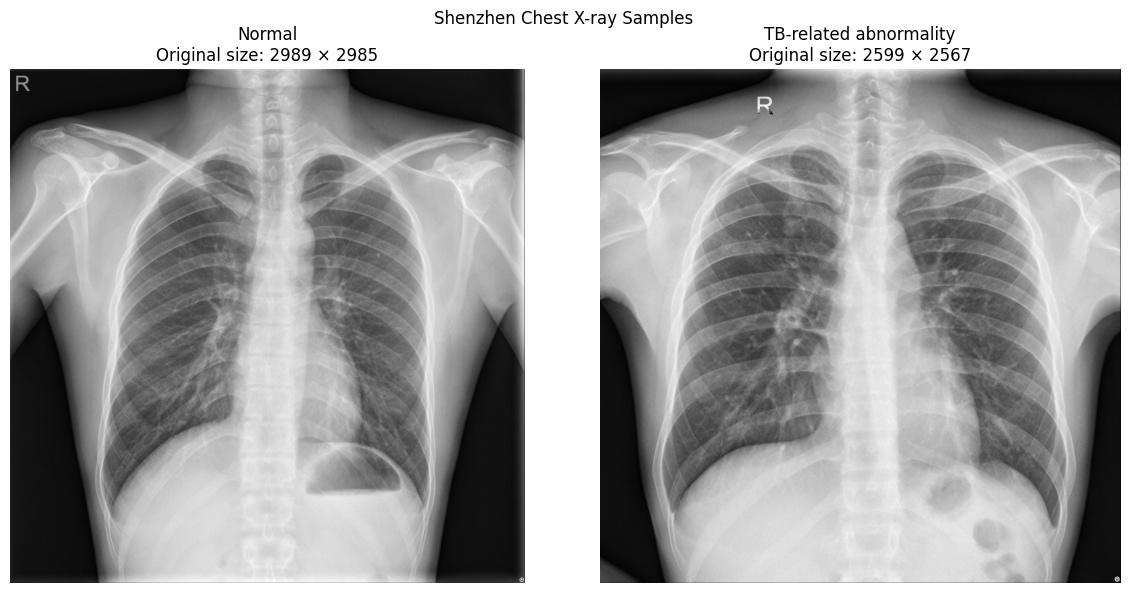

Images checked: 50
Unreadable images: 0
Image dimensions:
(3000, 2939)    2
(3000, 2943)    2
(2324, 2344)    1
(2679, 2967)    1
(2975, 2941)    1
(3000, 2963)    1
(3000, 2931)    1
(2983, 2959)    1
(2779, 2987)    1
(2387, 2793)    1
(1233, 1110)    1
(1836, 1811)    1
(2849, 2921)    1
(2495, 2854)    1
(2529, 2786)    1
(2991, 2995)    1
(2330, 2418)    1
(2989, 2985)    1
(3000, 2947)    1
(2588, 2994)    1
(3000, 2927)    1
(2709, 2639)    1
(2602, 2988)    1
(2986, 2992)    1
(2504, 2826)    1
(2775, 2948)    1
(2260, 2203)    1
(2998, 2857)    1
(3000, 2955)    1
(2516, 2603)    1
(2408, 2867)    1
(3000, 2945)    1
(3000, 2941)    1
(3000, 2937)    1
(2991, 2993)    1
(2758, 2938)    1
(3000, 2951)    1
(2646, 2992)    1
(2533, 2416)    1
(2996, 2989)    1
(2488, 2818)    1
(2704, 2948)    1
(2556, 2365)    1
(2400, 2599)    1
(2254, 2398)    1
(2689, 3001)    1
(3000, 2925)    1
(1615, 1772)    1
Name: count, dtype: int64


In [9]:
#Image Visualization and Dimension Check

from PIL import Image
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 6))

for label, ax in zip([0, 1], axes):
    sample = train_tb[train_tb["label"] == label].iloc[0]

    with Image.open(sample["image_path"]) as img:
        image = img.convert("L")
        width, height = image.size
        ax.imshow(image, cmap="gray")

    ax.set_title(
        f"{'Normal' if label == 0 else 'TB-related abnormality'}\n"
        f"Original size: {width} × {height}"
    )
    ax.axis("off")

plt.suptitle("Shenzhen Chest X-ray Samples")
plt.tight_layout()
plt.show()

# Sample Image Dimension Check
sample_paths = train_tb["image_path"].sample(
    n=min(50, len(train_tb)),
    random_state=42
)

dimensions = []
unreadable = 0

for path in sample_paths:
    try:
        with Image.open(path) as img:
            dimensions.append(img.size)
            img.verify()
    except Exception:
        unreadable += 1

print("Images checked:", len(sample_paths))
print("Unreadable images:", unreadable)
print("Image dimensions:")
print(pd.Series(dimensions).value_counts())


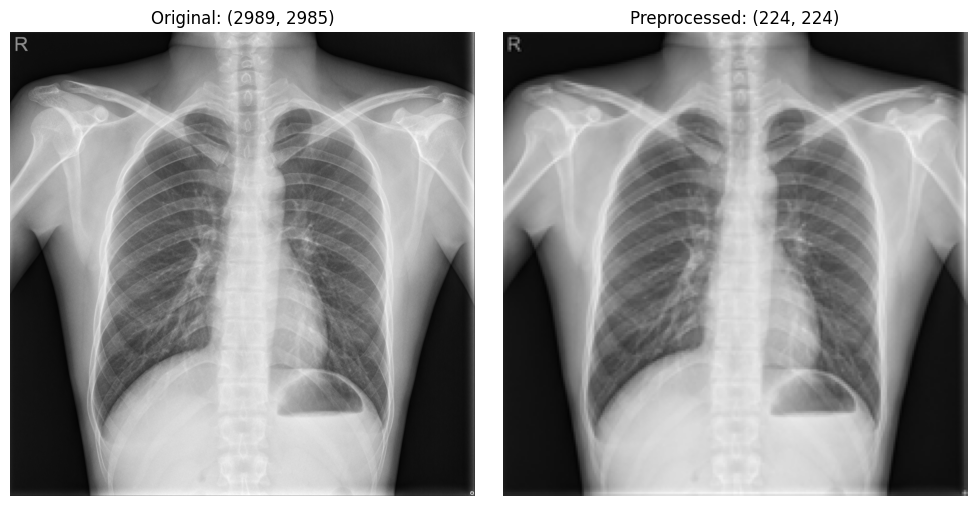

Original dimensions: (2989, 2985)
Preprocessed dimensions: (224, 224)
Preprocessed mode: RGB


In [10]:
# TB Image Preprocessing

from PIL import Image, ImageOps
import matplotlib.pyplot as plt

IMAGE_SIZE = 224

def preprocess_tb_image(image_path):
    with Image.open(image_path) as img:
        img = img.convert("RGB")
        img.thumbnail(
            (IMAGE_SIZE, IMAGE_SIZE),
            Image.Resampling.LANCZOS
        )
        img = ImageOps.pad(
            img,
            (IMAGE_SIZE, IMAGE_SIZE),
            color=(0, 0, 0)
        )
        return img.copy()

# Compare Original and Preprocessed Image
sample_path = train_tb.iloc[0]["image_path"]

with Image.open(sample_path) as img:
    original = img.convert("RGB").copy()

processed = preprocess_tb_image(sample_path)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(original)
axes[0].set_title(f"Original: {original.size}")
axes[0].axis("off")

axes[1].imshow(processed)
axes[1].set_title(f"Preprocessed: {processed.size}")
axes[1].axis("off")

plt.tight_layout()
plt.show()

print("Original dimensions:", original.size)
print("Preprocessed dimensions:", processed.size)
print("Preprocessed mode:", processed.mode)


In [11]:
# Save TB Preprocessing Function

PREPROCESS_FILE = OUTPUT_DIR / "tb_preprocessing.py"

code = '''
from PIL import Image, ImageOps

IMAGE_SIZE = 224

def preprocess_tb_image(image_path):
    with Image.open(image_path) as img:
        img = img.convert("RGB")
        img.thumbnail(
            (IMAGE_SIZE, IMAGE_SIZE),
            Image.Resampling.LANCZOS
        )
        img = ImageOps.pad(
            img,
            (IMAGE_SIZE, IMAGE_SIZE),
            color=(0, 0, 0)
        )
        return img.copy()
'''

PREPROCESS_FILE.write_text(code)

print("Preprocessing file saved:", PREPROCESS_FILE.exists())
print("Location:", PREPROCESS_FILE)


Preprocessing file saved: True
Location: /content/drive/MyDrive/Major_Project/Tuberculosis/outputs/tb_preprocessing.py
